# Inferring $\varepsilon$-machines from stochastic simulations

- Gillespie 2A <=> A2
- MAPK
- WCM module (e.g. Thornburg)

In [1]:
using Pkg; Pkg.activate(".")

using ComputationalMechanics
using Catalyst, JumpProcesses, Plots

  Activating project at `~/.julia/dev/ComputationalMechanics/notebooks`


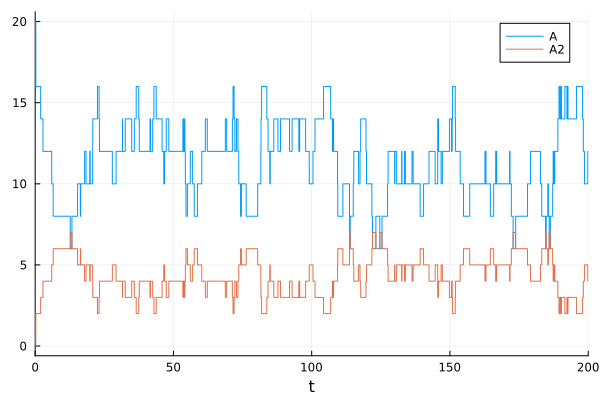

In [28]:
# simple stochastic (Gillespie) simulation of the chemical reaction 2A <=> A_2
rn = @reaction_network begin
    kf, 2A --> A2
    kr, A2 --> 2A
end

A0 = 20
u0 = [:A => A0, :A2 => 0]
p  = [:kf => 0.01, :kr => 0.1]
tspan = (0.0, 200.0)

jprob = JumpProblem(rn, u0, tspan, p)
sol   = solve(jprob, SSAStepper())
plot(sol)

In [31]:
@show a2_sequence = sol[:A2]
@show alphabet = 0:(A0 ÷ 2) 

inference = infer_machine(CSSR(), a2_sequence;
    alphabet,
    max_history=6,
    min_count=5,
    alpha = 0.001
)

a2_sequence = sol[:A2] = [0, 1, 2, 3, 4, 5, 6, 7, 6, 5, 6, 5, 4, 5, 4, 5, 4, 3, 2, 3, 4, 5, 4, 3, 4, 3, 4, 3, 2, 3, 4, 3, 4, 3, 2, 3, 4, 5, 4, 3, 4, 3, 4, 3, 4, 3, 4, 5, 6, 5, 4, 5, 6, 5, 4, 3, 4, 3, 4, 3, 2, 3, 4, 3, 4, 5, 6, 5, 6, 5, 4, 3, 2, 3, 4, 5, 4, 3, 4, 3, 4, 3, 2, 3, 4, 3, 4, 5, 4, 3, 2, 3, 4, 3, 4, 5, 6, 5, 6, 7, 6, 5, 4, 5, 4, 3, 4, 5, 6, 7, 6, 7, 6, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 6, 5, 4, 5, 4, 3, 4, 5, 4, 3, 4, 3, 2, 3, 4, 5, 6, 5, 4, 5, 6, 5, 4, 5, 4, 5, 6, 7, 6, 5, 4, 5, 6, 7, 6, 5, 6, 7, 6, 5, 4, 5, 4, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 4, 5, 4, 4]
alphabet = 0:A0 ÷ 2 = 0:10


Inference Result:
  algorithm = CSSR
  sequence_length = 182
  max_history = 6
  min_count = 5
  alpha = 0.001
  causal_states = 7
  transitions = 14

In [ ]:
machine = inference.machine
# TODO alphabet is incorrectly taken as chars, should take integer values

EpsilonMachine{Char}
  alphabet: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
  states: 7
  transitions: 14

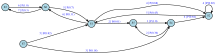

In [33]:
plot_machine(machine)
to_dot_file(machine, "gillespie.dot")

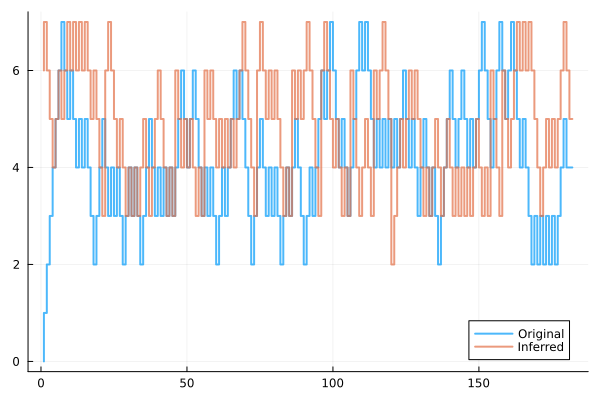

In [59]:
a2_inferred = simulate(Vector, machine, length(a2_sequence))
a2_inferred = parse.(Int, a2_inferred)

plot(a2_sequence, label="Original", lw=2, alpha=0.7, linetype=:steppre)
plot!(a2_inferred, label="Inferred", lw=2, alpha=0.7, linetype=:steppre)

In [ ]:
# TODO test statistical properties of ensembles of simulation and epsilon machine
# i.e. mean and variance